In [1]:
import pandas as pd

In [2]:
raw = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
raw.shape

(7043, 21)

In [3]:
tc = pd.to_numeric(raw["TotalCharges"], errors="coerce")
bad = raw[tc.isna()]
len(bad)

11

In [4]:
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
(bad["tenure"] == 0).all()

np.True_

In [6]:
(raw["tenure"] == 0).sum()

np.int64(11)

In [7]:
clean = raw.copy()
clean["TotalCharges"] = tc.fillna(0)
clean = clean.drop(columns="customerID")

In [8]:
clean.shape

(7043, 20)

In [9]:
clean.isna().sum().sum()

np.int64(0)

In [10]:
clean["TotalCharges"].dtype

dtype('float64')

In [11]:
raw["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
raw["customerID"].duplicated().sum()

np.int64(0)

In [13]:
clean.duplicated().sum()

np.int64(22)

In [14]:
cols3 = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
         "TechSupport", "StreamingTV", "StreamingMovies"]
pd.DataFrame({c: clean[c].value_counts() for c in cols3}).T

,No,No internet service,No phone service,Yes
MultipleLines,3390.0,NaN,682.0,2971.0
OnlineSecurity,3498.0,1526.0,NaN,2019.0
OnlineBackup,3088.0,1526.0,NaN,2429.0
DeviceProtection,3095.0,1526.0,NaN,2422.0
TechSupport,3473.0,1526.0,NaN,2044.0
StreamingTV,2810.0,1526.0,NaN,2707.0
StreamingMovies,2785.0,1526.0,NaN,2732.0


In [15]:
(clean["OnlineSecurity"] == "No internet service").sum()

np.int64(1526)

In [16]:
(clean["InternetService"] == "No").sum()

np.int64(1526)

In [17]:
(clean["MultipleLines"] == "No phone service").sum()

np.int64(682)

In [18]:
(clean["PhoneService"] == "No").sum()

np.int64(682)

In [19]:
clean[cols3] = clean[cols3].replace({"No internet service": "No",
                                     "No phone service": "No"})

In [20]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
rows = []
for c in num_cols:
    s = clean[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"cột": c, "Q1": q1, "Q3": q3, "IQR": iqr,
                 "ngưỡng dưới": low, "ngưỡng trên": high,
                 "số outlier": int(((s < low) | (s > high)).sum())})
pd.DataFrame(rows)

,cột,Q1,Q3,IQR,ngưỡng dưới,ngưỡng trên,số outlier
0,tenure,9.00,55.00,46.00,-60.000,124.000,0
1,MonthlyCharges,35.50,89.85,54.35,-46.025,171.375,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.525,8868.675,0


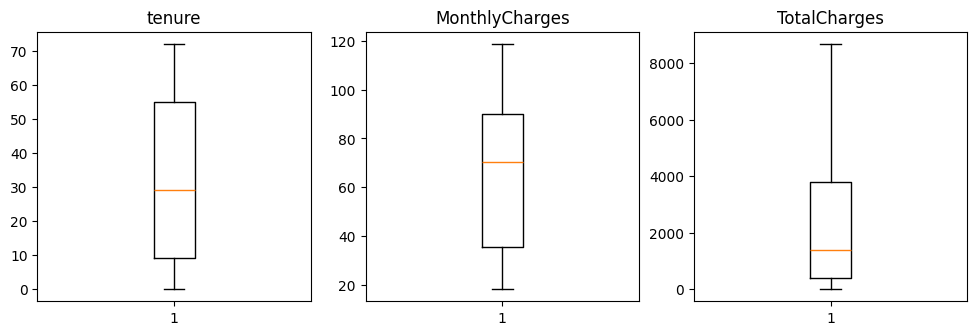

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, num_cols):
    ax.boxplot(clean[c])
    ax.set_title(c)
plt.show()

In [22]:
clean["Churn_num"] = (clean["Churn"] == "Yes").astype(int)
clean["Churn_num"].mean()

np.float64(0.2653698707936959)

In [23]:
clean.groupby("Contract")["Churn_num"].mean()

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn_num, dtype: float64

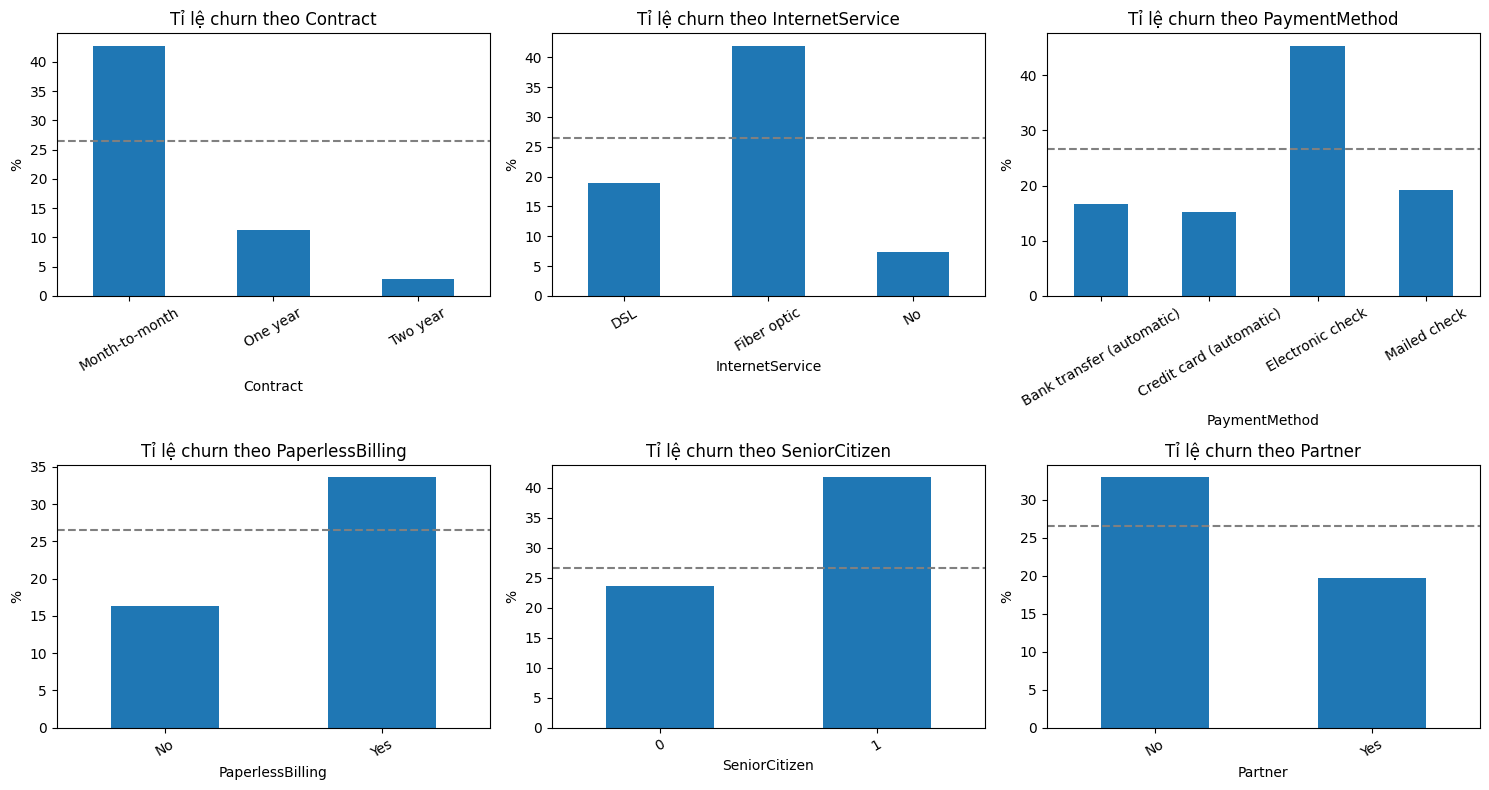

In [24]:
cols = ["Contract", "InternetService", "PaymentMethod",
        "PaperlessBilling", "SeniorCitizen", "Partner"]
overall = clean["Churn_num"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cols):
    rate = clean.groupby(c)["Churn_num"].mean() * 100
    rate.plot(kind="bar", ax=ax)
    ax.axhline(overall, ls="--", color="gray")
    ax.set_title(f"Tỉ lệ churn theo {c}")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

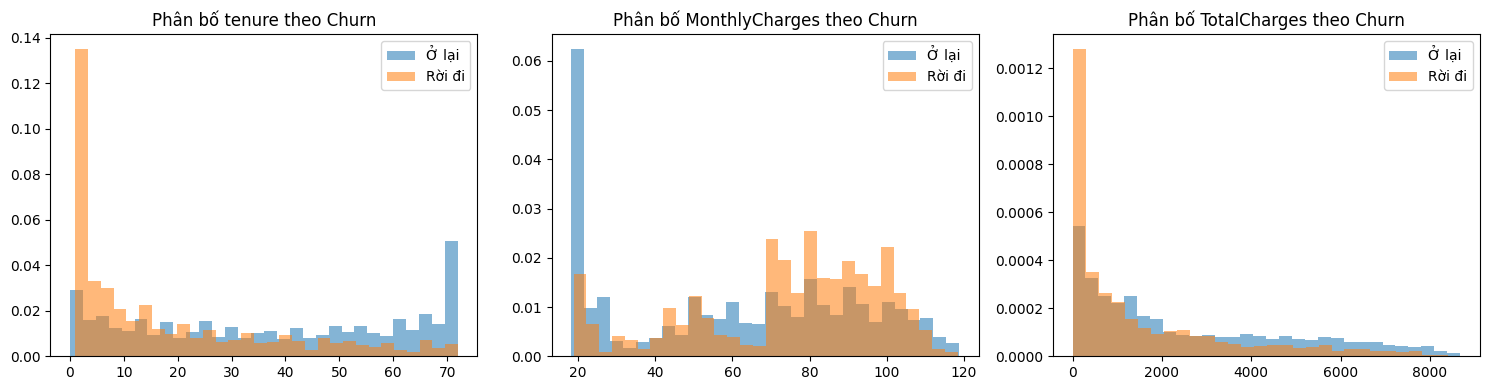

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for val, label in [(0, "Ở lại"), (1, "Rời đi")]:
        ax.hist(clean.loc[clean["Churn_num"] == val, c],
                bins=30, alpha=0.55, density=True, label=label)
    ax.set_title(f"Phân bố {c} theo Churn")
    ax.legend()
plt.tight_layout()
plt.show()

In [26]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_num"]
clean[corr_cols].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn_num
tenure,1.00,0.25,0.83,0.02,-0.35
MonthlyCharges,0.25,1.00,0.65,0.22,0.19
TotalCharges,0.83,0.65,1.00,0.10,-0.20
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
Churn_num,-0.35,0.19,-0.20,0.15,1.00


Quan sát: khách rời đi tập trung ở tenure thấp (0–5 tháng) và MonthlyCharges cao (70–105 USD). tenure và TotalCharges tương quan 0,83.
Quyết định: giữ cả ba thuộc tính số cho tới bước chọn đặc trưng.
Lý do: TotalCharges dư thừa với tenure × MonthlyCharges, nhưng cần kiểm chứng trên tập train trước khi loại.

In [27]:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]

feat = clean.copy()
feat["n_services"] = (feat[addon_cols] == "Yes").sum(axis=1).astype(int)
feat["tenure_group"] = pd.cut(feat["tenure"],
                              bins=[-1, 12, 24, 48, float("inf")],
                              labels=["0-12", "13-24", "25-48", "49+"]).astype(str)

print(feat["n_services"].value_counts().sort_index())
print(feat["tenure_group"].value_counts().reindex(["0-12", "13-24", "25-48", "49+"]))
print(feat.groupby("tenure_group")["Churn_num"].mean().reindex(["0-12", "13-24", "25-48", "49+"]).round(3))
print(feat.groupby("n_services")["Churn_num"].mean().round(3))

n_services
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64
tenure_group
0-12     2186
13-24    1024
25-48    1594
49+      2239
Name: count, dtype: int64
tenure_group
0-12     0.474
13-24    0.287
25-48    0.204
49+      0.095
Name: Churn_num, dtype: float64
n_services
0    0.214
1    0.458
2    0.358
3    0.274
4    0.223
5    0.124
6    0.053
Name: Churn_num, dtype: float64


In [28]:
from sklearn.model_selection import train_test_split

X = feat.drop(columns=["Churn", "Churn_num"])   # loại cả nhãn lẫn cột phụ để tránh target leakage
y = feat["Churn_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print("churn train:", round(y_train.mean(), 4), "| churn test:", round(y_test.mean(), 4))
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

(5634, 21) (1409, 21)
churn train: 0.2654 | churn test: 0.2654
{0: 4139, 1: 1495} {0: 1035, 1: 374}


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "n_services"]  # ghi đè num_cols cũ (3 cột, chỉ dùng cho IQR)
bin_pass = ["SeniorCitizen"]
cat_cols = [c for c in X_train.columns if c not in num_cols + bin_pass]
print(len(cat_cols), cat_cols)

encoder = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_pass),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
], verbose_feature_names_out=False)

Xtr = pd.DataFrame(encoder.fit_transform(X_train),
                   columns=encoder.get_feature_names_out(), index=X_train.index)
Xte = pd.DataFrame(encoder.transform(X_test),
                   columns=encoder.get_feature_names_out(), index=X_test.index)

print(X_train.shape, "->", Xtr.shape)
print(Xtr[num_cols].describe().loc[["mean", "std"]].round(3))
print(Xte[num_cols].describe().loc[["mean", "std"]].round(3))

16 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']
(5634, 21) -> (5634, 31)
      tenure  MonthlyCharges  TotalCharges  n_services
mean    -0.0            -0.0           0.0         0.0
std      1.0             1.0           1.0         1.0
      tenure  MonthlyCharges  TotalCharges  n_services
mean  -0.023          -0.028        -0.043      -0.054
std    0.998           0.992         0.972       0.980


In [30]:
from sklearn.feature_selection import mutual_info_classif

# (a) các cặp tương quan cao
corr = Xtr.corr()
cols = corr.columns
pairs = [(a, b, round(corr.loc[a, b], 2))
         for i, a in enumerate(cols) for b in cols[i+1:]
         if abs(corr.loc[a, b]) >= 0.7]
pairs_df = pd.DataFrame(pairs, columns=["feat_a", "feat_b", "r"])
print(pairs_df.reindex(pairs_df["r"].abs().sort_values(ascending=False).index).to_string(index=False))

# (b) mutual information với nhãn (số đã z-score = liên tục, còn lại = rời rạc)
discrete = [c not in num_cols for c in Xtr.columns]
mi = mutual_info_classif(Xtr, y_train, discrete_features=discrete, random_state=42)
mi_s = pd.Series(mi, index=Xtr.columns).sort_values(ascending=False).round(4)
print(mi_s.to_string())

        feat_a                      feat_b     r
        tenure            tenure_group_49+  0.85
        tenure                TotalCharges  0.83
MonthlyCharges InternetService_Fiber optic  0.79
MonthlyCharges          InternetService_No -0.76
        tenure           tenure_group_0-12 -0.75
  TotalCharges                  n_services  0.74
MonthlyCharges                  n_services  0.73
  TotalCharges            tenure_group_49+  0.73
Contract_Month-to-month                    0.0926
tenure                                     0.0671
Contract_Two year                          0.0605
InternetService_Fiber optic                0.0493
tenure_group_0-12                          0.0470
PaymentMethod_Electronic check             0.0461
MonthlyCharges                             0.0437
TotalCharges                               0.0387
tenure_group_49+                           0.0371
InternetService_No                         0.0318
n_services                                 0.0316
Paperless

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

def make_encoder(drop=()):
    nums = [c for c in num_cols if c not in drop]
    cats = [c for c in cat_cols if c not in drop]
    bins = [c for c in bin_pass if c not in drop]
    return ColumnTransformer([
        ("num", StandardScaler(), nums),
        ("bin", "passthrough", bins),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cats),
    ], verbose_feature_names_out=False)

def cv_auc(drop=()):
    pipe = Pipeline([("enc", make_encoder(drop)),
                     ("lr", LogisticRegression(max_iter=1000))])
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    s = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="roc_auc")
    return round(s.mean(), 4), round(s.std(), 4)

configs = {
    "đủ thuộc tính":               [],
    "bỏ TotalCharges":             ["TotalCharges"],
    "bỏ tenure_group":             ["tenure_group"],
    "bỏ gender, PhoneService":     ["gender", "PhoneService"],
}
for name, drop in configs.items():
    print(f"{name:28s} AUC (mean, std) =", cv_auc(drop))

đủ thuộc tính                AUC (mean, std) = (np.float64(0.8464), np.float64(0.0116))
bỏ TotalCharges              AUC (mean, std) = (np.float64(0.8463), np.float64(0.0115))
bỏ tenure_group              AUC (mean, std) = (np.float64(0.8461), np.float64(0.0125))
bỏ gender, PhoneService      AUC (mean, std) = (np.float64(0.8468), np.float64(0.0118))


In [32]:
print("đủ thuộc tính          :", [float(v) for v in cv_auc([])])
print("bỏ cả 3 (đề xuất)      :", [float(v) for v in cv_auc(["TotalCharges", "gender", "PhoneService"])])

đủ thuộc tính          : [0.8464, 0.0116]
bỏ cả 3 (đề xuất)      : [0.8466, 0.0116]


In [33]:
DROP_COLS = ["TotalCharges", "gender", "PhoneService"]

In [34]:
import numpy as np
import telco_prep as tp          # telco_prep.py phải nằm cùng thư mục với notebook
# import importlib; importlib.reload(tp)   # bỏ dấu # nếu bạn vừa thay nội dung file sau khi đã import

# 1. chia train/test trên dữ liệu THÔ (giữ customerID, Churn dạng Yes/No)
Xr_train, Xr_test, yr_train, yr_test = tp.split_data(raw)
assert (Xr_train.index == X_train.index).all() and (Xr_test.index == X_test.index).all()
print("Cách chia của module trùng với cách chia thủ công ở bước 10.")

# 2. dựng pipeline với DROP_COLS đã chốt, fit CHỈ trên train
pipe = tp.build_pipeline(DROP_COLS)
Xt_train = pipe.fit_transform(Xr_train)
Xt_test = pipe.transform(Xr_test)
names = tp.feature_names(pipe)

assert not np.isnan(Xt_train).any() and not np.isnan(Xt_test).any()
print(Xr_train.shape, "->", Xt_train.shape, "|", Xr_test.shape, "->", Xt_test.shape)

# 3. đối chiếu với encoder làm thủ công ở bước 13
manual = make_encoder(DROP_COLS).fit(X_train)
m_names = list(manual.get_feature_names_out())
assert sorted(names) == sorted(m_names)
a = pd.DataFrame(Xt_train, columns=names)[sorted(names)].to_numpy()
b = pd.DataFrame(manual.transform(X_train), columns=m_names)[sorted(names)].to_numpy()
print("Khớp với bản thủ công:", np.allclose(a, b))
print(len(names), names)

Cách chia của module trùng với cách chia thủ công ở bước 10.
(5634, 20) -> (5634, 28) | (1409, 20) -> (1409, 28)
Khớp với bản thủ công: True
28 ['tenure', 'MonthlyCharges', 'n_services', 'SeniorCitizen', 'Partner_Yes', 'Dependents_Yes', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure_group_0-12', 'tenure_group_13-24', 'tenure_group_25-48', 'tenure_group_49+']


In [35]:
import json, joblib
from pathlib import Path

PROC_DIR, MODEL_DIR = Path("data/processed"), Path("models")
PROC_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# --- xuất
Xr_train.to_csv(PROC_DIR / "X_train.csv", index=False)
Xr_test.to_csv(PROC_DIR / "X_test.csv", index=False)
yr_train.to_csv(PROC_DIR / "y_train.csv", index=False)   # cột tên "Churn", giá trị 1/0
yr_test.to_csv(PROC_DIR / "y_test.csv", index=False)

joblib.dump(pipe, MODEL_DIR / "preprocessor_fitted.joblib")
config = {
    "target": tp.TARGET,
    "random_state": tp.RANDOM_STATE,
    "test_size": tp.TEST_SIZE,
    "drop_cols": DROP_COLS,
    "train_rows": int(len(Xr_train)),
    "test_rows": int(len(Xr_test)),
    "n_features_after_encoding": len(names),
    "feature_names": names,
}
(MODEL_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã xuất:", sorted(p.name for p in list(PROC_DIR.iterdir()) + list(MODEL_DIR.iterdir())))

# --- kiểm tra 1: nạp lại .joblib cho kết quả y hệt
pipe_loaded = joblib.load(MODEL_DIR / "preprocessor_fitted.joblib")
assert np.allclose(pipe_loaded.transform(Xr_test), Xt_test)
print("1. Nạp lại .joblib: khớp.")

# --- kiểm tra 2: đọc lại CSV (như đồng đội) rồi transform vẫn khớp
X_test_csv = pd.read_csv(PROC_DIR / "X_test.csv")
assert np.allclose(pipe_loaded.transform(X_test_csv), Xt_test)
print("2. Đọc lại X_test.csv rồi transform: khớp.")

# --- kiểm tra 3: đầu vào kiểu dashboard (một dòng, không có customerID, TotalCharges)
one_row = Xr_test.iloc[[0]].drop(columns=["customerID", "TotalCharges"])
print("3. Một dòng kiểu dashboard ->", pipe_loaded.transform(one_row).shape)

# --- kiểm tra 4: ghép với mô hình trong cross-validation, kết quả phải trùng bước 13
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
model_pipe = tp.with_model(LogisticRegression(max_iter=1000), DROP_COLS)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
s = cross_val_score(model_pipe, Xr_train, yr_train, cv=skf, scoring="roc_auc")
print("4. AUC CV qua module:", round(float(s.mean()), 4), "(bước 13 bỏ cả 3: 0.8466)")

Đã xuất: ['X_test.csv', 'X_train.csv', 'bang_truoc_sau_xu_ly.csv', 'config.json', 'preprocessor_fitted.joblib', 'y_test.csv', 'y_train.csv']
1. Nạp lại .joblib: khớp.
2. Đọc lại X_test.csv rồi transform: khớp.
3. Một dòng kiểu dashboard -> (1, 28)
4. AUC CV qua module: 0.8466 (bước 13 bỏ cả 3: 0.8466)


In [36]:
import telco_prep as tp
from sklearn.linear_model import LogisticRegression

df = tp.load_data("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X_train, X_test, y_train, y_test = tp.split_data(df)        # chia chung, seed 42
pipe = tp.with_model(LogisticRegression(max_iter=1000), drop_cols=["TotalCharges", "gender", "PhoneService"])
pipe.fit(X_train, y_train)                                  # mọi tiền xử lý nằm trong pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('encode', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['customerID','gender','SeniorCitizen',...,'PaymentMethod', 'MonthlyCharges','TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...001E9167BF100>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [37]:
# 1. trùng lặp (mục 2.3)
dup_ids = int(raw["customerID"].duplicated().sum())
dup_rows = int(raw.drop(columns="customerID").duplicated().sum())
print("customerID trùng:", dup_ids, "| dòng giống hệt (không tính ID):", dup_rows)

# 2. xác nhận mỗi cột dịch vụ chỉ còn Yes/No sau khi gộp nhãn
print(pd.DataFrame({c: clean[c].value_counts() for c in cols3}).T.fillna(0).astype(int))

# 3. bảng trước/sau tiền xử lý
three_level = [c for c in cols3]
before_after = pd.DataFrame({
    "Trước xử lý (file gốc)": {
        "Số dòng": len(raw),
        "Số cột (gồm customerID, Churn)": raw.shape[1],
        "Cột dạng chữ (trừ customerID)": int(raw.drop(columns="customerID").select_dtypes(exclude="number").shape[1]),
        "Ô TotalCharges không phải số": int(tc.isna().sum()),
        "Nhãn 'No internet/phone service'": int(raw[three_level].isin(["No internet service", "No phone service"]).sum().sum()),
    },
    "Sau xử lý (vào mô hình)": {
        "Số dòng": len(Xt_train) + len(Xt_test),
        "Số cột (gồm customerID, Churn)": len(names),
        "Cột dạng chữ (trừ customerID)": 0,
        "Ô TotalCharges không phải số": 0,
        "Nhãn 'No internet/phone service'": 0,
    },
})
before_after.rename(index={"Số cột (gồm customerID, Churn)": "Số cột / số đặc trưng"}, inplace=True)
display(before_after)
before_after.to_csv(PROC_DIR / "bang_truoc_sau_xu_ly.csv", encoding="utf-8-sig")

customerID trùng: 0 | dòng giống hệt (không tính ID): 22
                    No   Yes
MultipleLines     4072  2971
OnlineSecurity    5024  2019
OnlineBackup      4614  2429
DeviceProtection  4621  2422
TechSupport       4999  2044
StreamingTV       4336  2707
StreamingMovies   4311  2732


C:\Users\Admin\AppData\Local\Temp\ipykernel_14828\1642083701.py:27: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  before_after.rename(index={"Số cột (gồm customerID, Churn)": "Số cột / số đặc trưng"}, inplace=True)


,Trước xử lý (file gốc),Sau xử lý (vào mô hình)
Số dòng,7043,7043
Số cột / số đặc trưng,21,28
Cột dạng chữ (trừ customerID),17,0
Ô TotalCharges không phải số,11,0
Nhãn 'No internet/phone service',9838,0


In [38]:
before_after = before_after.rename(index={"Số cột (gồm customerID, Churn)": "Số cột / số đặc trưng"})

In [39]:
from scipy.stats import chi2_contingency

rows = []
for c in cat_cols:                                   # 16 thuộc tính phân loại, trên tập train
    ct = pd.crosstab(X_train[c], y_train)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = (chi2 / (len(X_train) * (min(ct.shape) - 1))) ** 0.5
    rows.append((c, round(chi2, 1), dof, p, round(v, 3)))

chi_tbl = (pd.DataFrame(rows, columns=["thuộc tính", "chi2", "dof", "p-value", "Cramér V"])
             .sort_values("Cramér V", ascending=False).reset_index(drop=True))
chi_tbl["p-value"] = chi_tbl["p-value"].map(lambda p: f"{p:.2e}")
display(chi_tbl)

KeyError: 'tenure_group'

In [ ]:
from scipy.stats import chi2_contingency

Xf_train = tp.prepare_features(Xr_train)       # train đã làm sạch + có n_services, tenure_group

rows = []
for c in tp.CATEGORICAL_COLS:                  # 16 thuộc tính phân loại
    ct = pd.crosstab(Xf_train[c], yr_train)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = (chi2 / (len(Xf_train) * (min(ct.shape) - 1))) ** 0.5
    rows.append((c, round(chi2, 1), dof, p, round(v, 3)))

chi_tbl = (pd.DataFrame(rows, columns=["thuộc tính", "chi2", "dof", "p-value", "Cramér V"])
             .sort_values("Cramér V", ascending=False).reset_index(drop=True))
chi_tbl["p-value"] = chi_tbl["p-value"].map(lambda p: f"{p:.2e}")
display(chi_tbl)

,thuộc tính,chi2,dof,p-value,Cramér V
0,Contract,952.3,2,1.62e-207,0.411
1,tenure_group,665.6,3,6.11e-144,0.344
2,InternetService,600.8,2,3.37e-131,0.327
3,PaymentMethod,545.2,3,7.57e-118,0.311
4,PaperlessBilling,219.9,1,9.40e-50,0.198
5,OnlineSecurity,170.8,1,4.84e-39,0.174
6,Dependents,157.2,1,4.71e-36,0.167
7,TechSupport,153.9,1,2.43e-35,0.165
8,Partner,119.0,1,1.06e-27,0.145
9,OnlineBackup,37.9,1,7.49e-10,0.082


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

num3 = ["tenure", "MonthlyCharges", "TotalCharges"]
A = Xf_train[num3]

mm  = pd.DataFrame(MinMaxScaler().fit_transform(A), columns=num3, index=A.index)
zs  = pd.DataFrame(StandardScaler().fit_transform(A), columns=num3, index=A.index)
dec = A / (10 ** (np.floor(np.log10(A.abs().max())) + 1))   # decimal scaling: chia 10^j sao cho |x'| < 1

parts = []
for name, D in [("Gốc", A), ("Min-max", mm), ("Decimal scaling", dec), ("Z-score", zs)]:
    s = D.agg(["min", "max", "mean", "std"]).T.round(3)
    s.insert(0, "phương pháp", name)
    parts.append(s)
cmp_tbl = pd.concat(parts).reset_index().rename(columns={"index": "thuộc tính"})
display(cmp_tbl)

,thuộc tính,phương pháp,min,max,mean,std
0,tenure,Gốc,0.000,72.000,32.485,24.569
1,MonthlyCharges,Gốc,18.400,118.750,64.930,30.138
2,TotalCharges,Gốc,0.000,8684.800,2299.335,2279.204
3,tenure,Min-max,0.000,1.000,0.451,0.341
4,MonthlyCharges,Min-max,0.000,1.000,0.464,0.300
5,TotalCharges,Min-max,0.000,1.000,0.265,0.262
6,tenure,Decimal scaling,0.000,0.720,0.325,0.246
7,MonthlyCharges,Decimal scaling,0.018,0.119,0.065,0.030
8,TotalCharges,Decimal scaling,0.000,0.868,0.230,0.228
9,tenure,Z-score,-1.322,1.608,-0.000,1.000


In [ ]:
def profile(binned, name):
    d = pd.DataFrame({"khoảng": binned.values, "churn": yr_train.values})
    g = d.groupby("khoảng", observed=True)["churn"].agg(["size", "mean"]).round(3)
    g.columns = ["số bản ghi", "tỉ lệ churn"]
    print("---", name)
    display(g)

t = Xf_train["tenure"]
profile(pd.cut(t, bins=4),  "Equal-width (4 khoảng bằng nhau)")
profile(pd.qcut(t, q=4),    "Equal-frequency (4 phân vị)")
profile(Xf_train["tenure_group"], "Theo nghiệp vụ (0-12, 13-24, 25-48, 49+)")

--- Equal-width (4 khoảng bằng nhau)


,số bản ghi,tỉ lệ churn
khoảng,,
"(-0.072, 18.0]",2191,0.439
"(18.0, 36.0]",1033,0.227
"(36.0, 54.0]",951,0.188
"(54.0, 72.0]",1459,0.082


--- Equal-frequency (4 phân vị)


,số bản ghi,tỉ lệ churn
khoảng,,
"(-0.001, 9.0]",1463,0.497
"(9.0, 29.0]",1377,0.287
"(29.0, 55.0]",1386,0.187
"(55.0, 72.0]",1408,0.081


--- Theo nghiệp vụ (0-12, 13-24, 25-48, 49+)


,số bản ghi,tỉ lệ churn
khoảng,,
0-12,1737,0.473
13-24,818,0.286
25-48,1290,0.202
49+,1789,0.099


 5 thành phần giữ 67.6% phương sai
10 thành phần giữ 81.1% phương sai
15 thành phần giữ 91.2% phương sai
20 thành phần giữ 98.5% phương sai
Số thành phần để đạt 90%: 15 | đạt 95%: 18 | tổng số chiều: 28


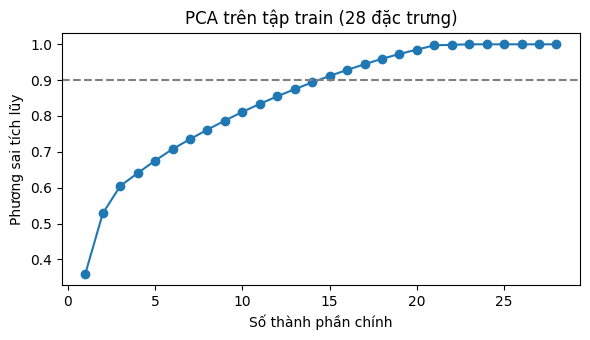

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA().fit(Xt_train)                       # Xt_train: train đã z-score + one-hot, 28 chiều
cum = np.cumsum(pca.explained_variance_ratio_)

for k in (5, 10, 15, 20):
    print(f"{k:2d} thành phần giữ {cum[k-1]*100:.1f}% phương sai")
print("Số thành phần để đạt 90%:", int(np.argmax(cum >= 0.90) + 1),
      "| đạt 95%:", int(np.argmax(cum >= 0.95) + 1), "| tổng số chiều:", Xt_train.shape[1])

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.90, ls="--", c="gray")
plt.xlabel("Số thành phần chính"); plt.ylabel("Phương sai tích lũy")
plt.title("PCA trên tập train (28 đặc trưng)"); plt.tight_layout(); plt.show()

In [ ]:
one = raw[raw["tenure"] == 1]
ratio = pd.to_numeric(one["TotalCharges"], errors="coerce") / one["MonthlyCharges"]
print(ratio.describe().round(2))

count    613.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


In [ ]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]
for c in addons:
    print(c, ((raw[c] == "No internet service") == (raw["InternetService"] == "No")).all())
print("MultipleLines", ((raw["MultipleLines"] == "No phone service") == (raw["PhoneService"] == "No")).all())

OnlineSecurity True
OnlineBackup True
DeviceProtection True
TechSupport True
StreamingTV True
StreamingMovies True
MultipleLines True


In [ ]:
for col in ["Contract", "InternetService", "PaymentMethod",
            "PaperlessBilling", "SeniorCitizen", "Partner"]:
    print(f"\n== {col} ==")
    print(clean.groupby(col)["Churn_num"].agg(["size", "mean"]).round(3))


== Contract ==


NameError: name 'clean' is not defined

In [40]:
for col in ["Contract", "InternetService", "PaymentMethod",
            "PaperlessBilling", "SeniorCitizen", "Partner"]:
    print(f"\n== {col} ==")
    print(clean.groupby(col)["Churn_num"].agg(["size", "mean"]).round(3))


== Contract ==
                size   mean
Contract                   
Month-to-month  3875  0.427
One year        1473  0.113
Two year        1695  0.028

== InternetService ==
                 size   mean
InternetService             
DSL              2421  0.190
Fiber optic      3096  0.419
No               1526  0.074

== PaymentMethod ==
                           size   mean
PaymentMethod                         
Bank transfer (automatic)  1544  0.167
Credit card (automatic)    1522  0.152
Electronic check           2365  0.453
Mailed check               1612  0.191

== PaperlessBilling ==
                  size   mean
PaperlessBilling             
No                2872  0.163
Yes               4171  0.336

== SeniorCitizen ==
               size   mean
SeniorCitizen             
0              5901  0.236
1              1142  0.417

== Partner ==
         size   mean
Partner             
No       3641  0.330
Yes      3402  0.197


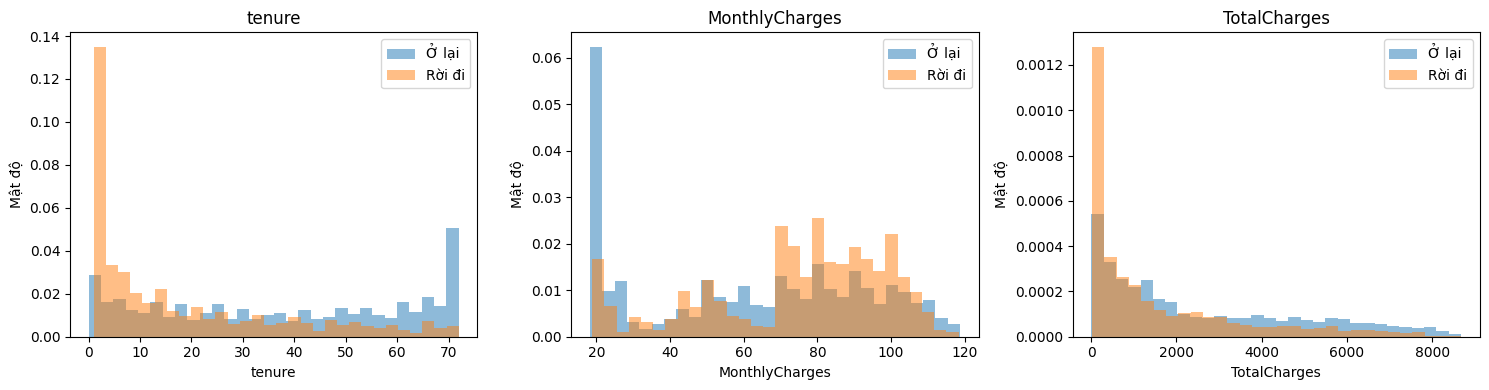

In [41]:
import matplotlib.pyplot as plt

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    for label, name in [(0, "Ở lại"), (1, "Rời đi")]:
        ax.hist(clean.loc[clean["Churn_num"] == label, col],
                bins=30, density=True, alpha=0.5, label=name)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Mật độ")
    ax.legend()
plt.tight_layout()
plt.show()

In [42]:
for label, name in [(0, "Ở lại"), (1, "Rời đi")]:
    s = clean.loc[clean["Churn_num"] == label, "tenure"]
    print(name, "| tenure<=2:", round((s <= 2).mean(), 3), "| tenure>=70:", round((s >= 70).mean(), 3))

Ở lại | tenure<=2: 0.069 | tenure>=70: 0.121
Rời đi | tenure<=2: 0.269 | tenure>=70: 0.012


In [43]:
for label, name in [(0, "Ở lại"), (1, "Rời đi")]:
    s = clean.loc[clean["Churn_num"] == label, "tenure"]
    print(name, "| tenure<=2:", round((s <= 2).mean(), 3), "| tenure>=70:", round((s >= 70).mean(), 3))

Ở lại | tenure<=2: 0.069 | tenure>=70: 0.121
Rời đi | tenure<=2: 0.269 | tenure>=70: 0.012


FileNotFoundError: [Errno 2] No such file or directory: 'image/eda-numeric-by-churn.png'

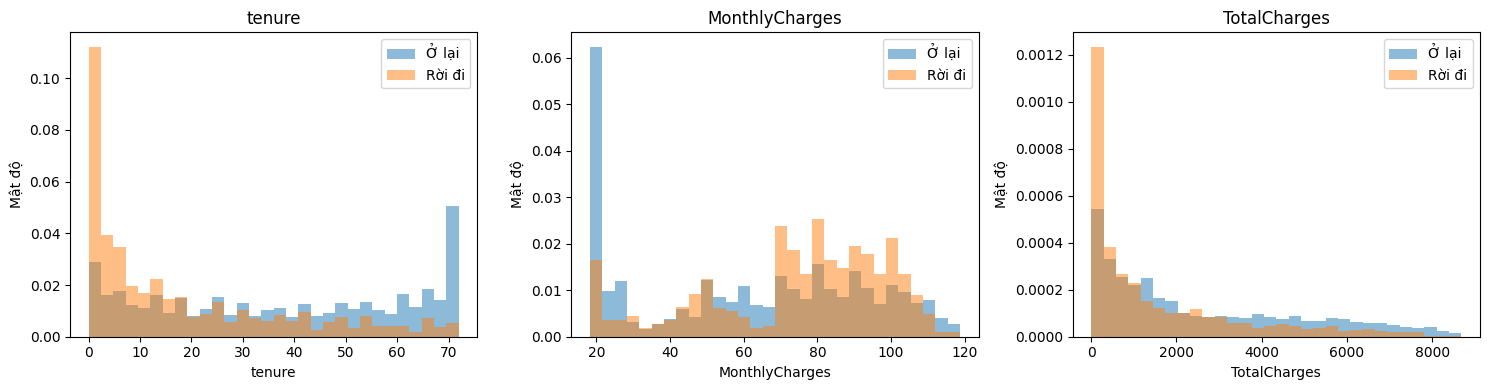

In [44]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    bins = np.linspace(clean[col].min(), clean[col].max(), 31)   # cùng bin cho cả hai lớp
    for label, name in [(0, "Ở lại"), (1, "Rời đi")]:
        ax.hist(clean.loc[clean["Churn_num"] == label, col],
                bins=bins, density=True, alpha=0.5, label=name)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Mật độ")
    ax.legend()
plt.tight_layout()
plt.savefig("image/eda-numeric-by-churn.png", dpi=200, bbox_inches="tight")
plt.show()

In [45]:
import os
os.makedirs("image", exist_ok=True)   # tạo thư mục image/ nếu chưa có
plt.savefig("image/eda-numeric-by-churn.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

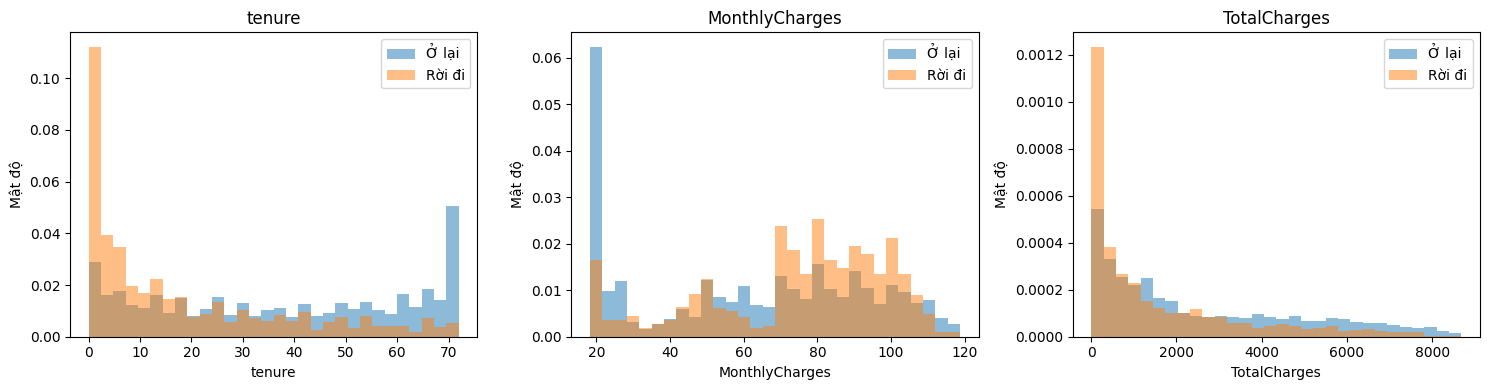

In [46]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    bins = np.linspace(clean[col].min(), clean[col].max(), 31)   # cùng bin cho cả hai lớp
    for label, name in [(0, "Ở lại"), (1, "Rời đi")]:
        ax.hist(clean.loc[clean["Churn_num"] == label, col],
                bins=bins, density=True, alpha=0.5, label=name)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Mật độ")
    ax.legend()
plt.tight_layout()
plt.savefig("image/eda-numeric-by-churn.png", dpi=200, bbox_inches="tight")
plt.show()